In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay, ConfusionMatrixDisplay
)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
df = pd.read_excel("/content/drive/MyDrive/machine learning/praktikum04/data/stunting_wasting_dataset.xlsx")
df.head()

,Jenis Kelamin,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg),Stunting,Wasting
0,Laki-laki,19,91.6,13.3,Tall,Risk of Overweight
1,Laki-laki,20,77.7,8.5,Stunted,Underweight
2,Laki-laki,10,79.0,10.3,Normal,Risk of Overweight
3,Perempuan,2,50.3,8.3,Severely Stunted,Risk of Overweight
4,Perempuan,5,56.4,10.9,Severely Stunted,Risk of Overweight


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Jenis Kelamin      100000 non-null  object 
 1   Umur (bulan)       100000 non-null  int64  
 2   Tinggi Badan (cm)  100000 non-null  float64
 3   Berat Badan (kg)   100000 non-null  float64
 4   Stunting           100000 non-null  object 
 5   Wasting            100000 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 4.6+ MB


In [5]:
df.isnull().sum()

,0
Jenis Kelamin,0
Umur (bulan),0
Tinggi Badan (cm),0
Berat Badan (kg),0
Stunting,0
Wasting,0


In [6]:
df['Stunting'].unique()

array(['Tall', 'Stunted', 'Normal', 'Severely Stunted'], dtype=object)

In [7]:
pd.array (['Tall','Stunted','Normal','Severely Stunted'], dtype=object)

<NumpyExtensionArray>
['Tall', 'Stunted', 'Normal', 'Severely Stunted']
Length: 4, dtype: object

In [8]:
df['Jenis Kelamin'].unique()

array(['Laki-laki', 'Perempuan'], dtype=object)

In [9]:
np.array(['Male','Female'], dtype=object)

array(['Male', 'Female'], dtype=object)

In [10]:
# 1. Mapping kolom Stunting -> biner
map_stunt = {'Stunted': 1, 'Severely Stunted': 1, 'Normal': 0, 'Tall': 0}
df['Stunting_bin'] = df['Stunting'].map(map_stunt).astype('Int64')

# 2. Mapping kolom Jenis Kelamin -> biner
# Laki-Laki = 1, Perempuan = 0
df['JK_bin'] = (df['Jenis Kelamin'] == 'Laki-laki').astype(int)

print("Distribusi Stunting_bin:\n", df['Stunting_bin'].value_counts())
print("\nDistribusi JK_bin:\n", df['JK_bin'].value_counts())

Distribusi Stunting_bin:
 Stunting_bin
0    78021
1    21979
Name: count, dtype: Int64

Distribusi JK_bin:
 JK_bin
1    50179
0    49821
Name: count, dtype: int64


In [11]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg),Stunting_bin,JK_bin
Umur (bulan),1.000000,0.875869,0.665389,0.038630,0.004046
Tinggi Badan (cm),0.875869,1.000000,0.626005,-0.283855,0.073505
Berat Badan (kg),0.665389,0.626005,1.000000,0.021090,0.045797
Stunting_bin,0.038630,-0.283855,0.021090,1.000000,-0.005981
JK_bin,0.004046,0.073505,0.045797,-0.005981,1.000000


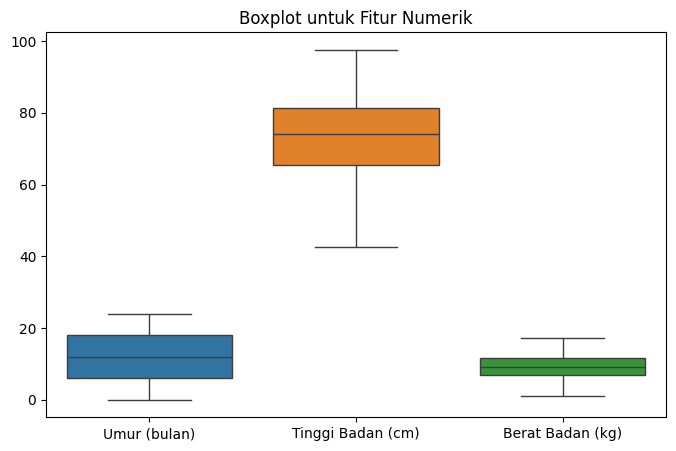

In [12]:

import seaborn as sns
import matplotlib.pyplot as plt

# Membuat boxplot untuk beberapa kolom numerik secara sekaligus
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[['Umur (bulan)', 'Tinggi Badan (cm)', 'Berat Badan (kg)']])
plt.title('Boxplot untuk Fitur Numerik')
plt.show()


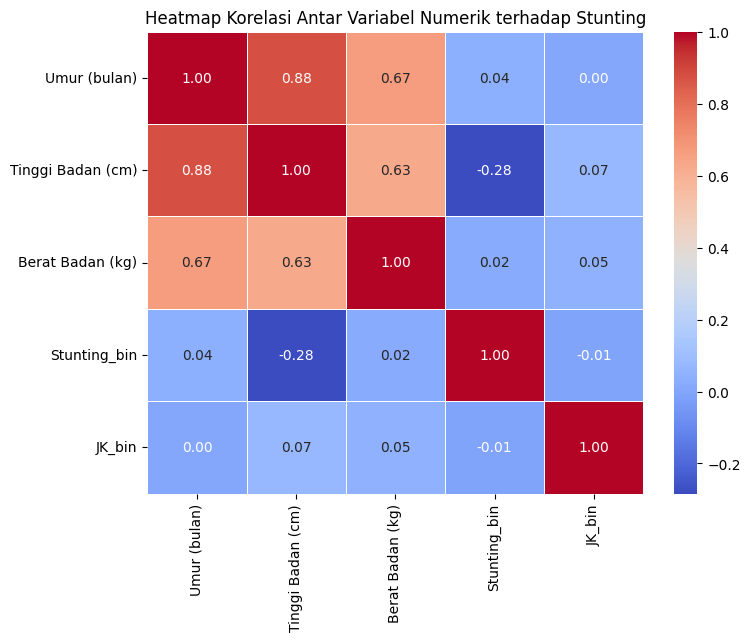

In [13]:
# Visualisasi heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Antar Variabel Numerik terhadap Stunting", fontsize=12)
plt.show()

In [14]:
# Fitur numerik dan gender
feature_num = ['Umur (bulan)', 'Tinggi Badan (cm)', 'Berat Badan (kg)']
feature_bin = ['JK_bin']

# Gabungkan & drop missing
use_cols = feature_num + feature_bin + ['Stunting_bin']
df_model = df[use_cols].dropna().copy()

X = df_model[feature_num + feature_bin]
y = df_model['Stunting_bin']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100000, 4)
y shape: (100000,)


In [15]:
# Menentukan fitur numerik dan gender
feature_num = ['Umur (bulan)', 'Tinggi Badan (cm)', 'Berat Badan (kg)']
feature_bin = ['JK_bin']

# Gabungkan & drop missing value (jika ada)
use_cols = feature_num + feature_bin + ['Stunting_bin']
df_model = df[use_cols].dropna().copy()

X = df_model[feature_num + feature_bin]
y = df_model['Stunting_bin']

print("X shape:", X.shape)
print("y shape:", y.shape)

# Split data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

X shape: (100000, 4)
y shape: (100000,)
Data latih: (80000, 4)
Data uji: (20000, 4)


In [16]:
# Scale hanya fitur numerik, gender langsung passthrough
preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), feature_num),
        ('bin', 'passthrough', feature_bin)
    ],
    remainder='drop'
)

# Inisialisasi model
model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    class_weight='balanced',
    random_state=42
)

# Gabungkan dalam Pipeline
clf = Pipeline([
    ('preprocess', preprocess),
    ('model', model)
])

# Latih model
clf.fit(X_train, y_train)
print("Model Logistic Regression berhasil dilatih.")

Model Logistic Regression berhasil dilatih.


In [17]:
# Prediksi & probabilitas
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

# Hitung metrik
print(f"Akurasi  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")

Akurasi  : 0.9055
Precision: 0.7152
Recall   : 0.9472
F1-Score : 0.8150
ROC-AUC  : 0.9656


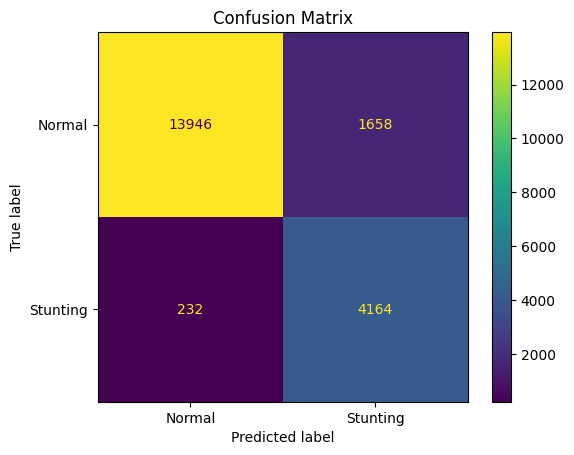

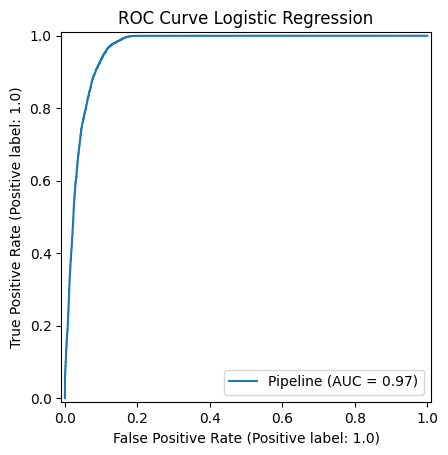

In [18]:
# Confusion Matrix
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=['Normal', 'Stunting']
).plot(values_format='d')
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.title("ROC Curve Logistic Regression")
plt.show()

In [19]:
from sklearn.model_selection import cross_val_score

# Classification Report
print(classification_report(y_test, y_pred, target_names=['Tidak Stunting (0)', 'Stunting (1)']))

# Cross Validation (5-fold)
scores = cross_val_score(clf, X, y, cv=5)

print("Skor tiap fold:", scores)
print("Rata-rata akurasi:", np.mean(scores))
print("Standar deviasi:", np.std(scores))

                    precision    recall  f1-score   support

Tidak Stunting (0)       0.98      0.89      0.94     15604
      Stunting (1)       0.72      0.95      0.82      4396

          accuracy                           0.91     20000
         macro avg       0.85      0.92      0.88     20000
      weighted avg       0.92      0.91      0.91     20000

Skor tiap fold: [0.9062  0.9013  0.9052  0.89905 0.9002 ]
Rata-rata akurasi: 0.9023899999999999
Standar deviasi: 0.0028125433329995106


In [20]:
# Ambil nama fitur & koefisien dari pipeline
feat_names = feature_num + feature_bin
coefs = clf.named_steps['model'].coef_[0]
odds = np.exp(coefs)

coef_df = pd.DataFrame({
    'Fitur': feat_names,
    'Koefisien (log-odds)': coefs,
    'Odds Ratio (e^coef)': odds
}).sort_values('Odds Ratio (e^coef)', ascending=False)

display(coef_df)

,Fitur,Koefisien (log-odds),Odds Ratio (e^coef)
0,Umur (bulan),8.525912,5043.782458
3,JK_bin,1.675944,5.343839
2,Berat Badan (kg),0.661090,1.936903
1,Tinggi Badan (cm),-10.535980,0.000027


In [21]:
# Membuat data uji baru
data_baru = pd.DataFrame({
    'Umur (bulan)': [24, 10],
    'Tinggi Badan (cm)': [79.0, 72.5],
    'Berat Badan (kg)': [9.2, 7.8],
    'JK_bin': [1, 0]  # 1 = Laki-Laki, 0 = Perempuan
})

# Prediksi kelas dan probabilitas
pred = clf.predict(data_baru)
prob = clf.predict_proba(data_baru)[:, 1]

# Menampilkan hasil
hasil = data_baru.copy()
hasil['Prob_Stunting'] = prob
hasil['Pred (0=Tidak, 1=Ya)'] = pred

display(hasil)

,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg),JK_bin,Prob_Stunting,"Pred (0=Tidak, 1=Ya)"
0,24,79.0,9.2,1,0.998208,1.0
1,10,72.5,7.8,0,0.002094,0.0


In [24]:
import pandas as pd

# 1. Read the CSV file with a comma delimiter
df_mobil = pd.read_csv('/content/drive/MyDrive/machine learning/praktikum04/data/calonpembelimobil.csv', sep=',')

# Cetak header data (5 baris pertama)
print(df_mobil.head())

   ID  Usia  Status  Kelamin  Memiliki_Mobil  Penghasilan  Beli_Mobil
0   1    32       1        0               0          240           1
1   2    49       2        1               1          100           0
2   3    52       1        0               2          250           1
3   4    26       2        1               1          130           0
4   5    45       3        0               2          237           1


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay, ConfusionMatrixDisplay
)

In [27]:
# Cek informasi kolom dan tipe data
df_mobil.info()

# Cek missing value
print("\nJumlah missing value:")
print(df_mobil.isnull().sum())

# Menentukan Fitur (X) dan Target (y)
# Fitur: Usia, Status, Kelamin, Memiliki_Mobil, Penghasilan
# Target: Beli_Mobil (0 = Tidak Beli, 1 = Beli)
X = df_mobil[['Usia', 'Status', 'Kelamin', 'Memiliki_Mobil', 'Penghasilan']]
y = df_mobil['Beli_Mobil']

print("X shape:", X.shape)
print("y shape:", y.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ID              1000 non-null   int64
 1   Usia            1000 non-null   int64
 2   Status          1000 non-null   int64
 3   Kelamin         1000 non-null   int64
 4   Memiliki_Mobil  1000 non-null   int64
 5   Penghasilan     1000 non-null   int64
 6   Beli_Mobil      1000 non-null   int64
dtypes: int64(7)
memory usage: 54.8 KB

Jumlah missing value:
ID                0
Usia              0
Status            0
Kelamin           0
Memiliki_Mobil    0
Penghasilan       0
Beli_Mobil        0
dtype: int64
X shape: (1000, 5)
y shape: (1000,)


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)

Data latih: (800, 5)
Data uji  : (200, 5)


In [29]:
# Feature Scaling untuk kolom kontinu
num_features = ['Usia', 'Penghasilan']
passthrough_features = ['Status', 'Kelamin', 'Memiliki_Mobil']

preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('pass', 'passthrough', passthrough_features)
    ]
)

# Inisialisasi Model Logistic Regression
model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    random_state=42
)

# Buat Pipeline
clf = Pipeline([
    ('preprocess', preprocess),
    ('model', model)
])

# Latih model
clf.fit(X_train, y_train)
print("Model Logistic Regression berhasil dilatih.")

Model Logistic Regression berhasil dilatih.


Akurasi   : 0.9350
Precision : 0.9672
Recall    : 0.9291
F1-Score  : 0.9478
ROC-AUC   : 0.9772


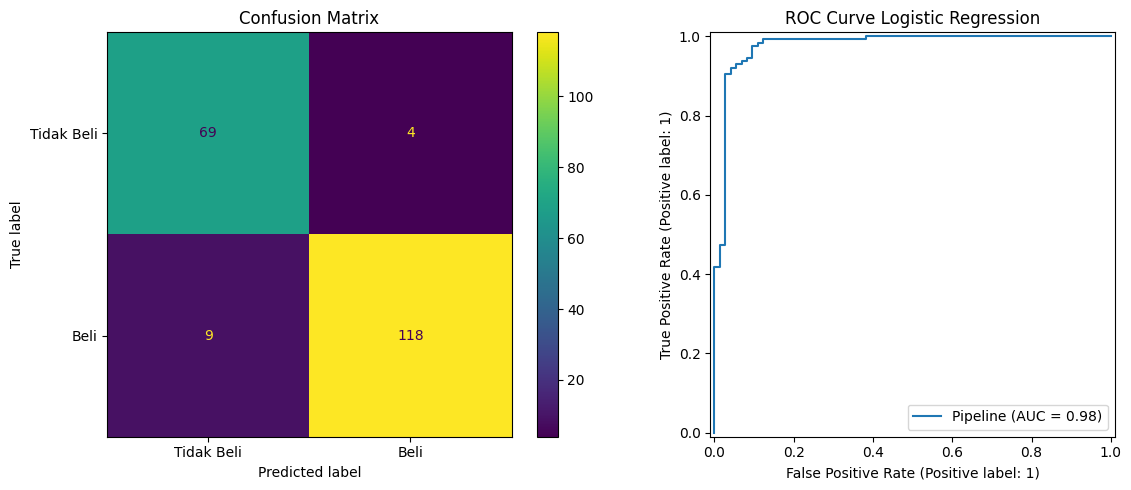


Classification Report:
                precision    recall  f1-score   support

Tidak Beli (0)       0.88      0.95      0.91        73
      Beli (1)       0.97      0.93      0.95       127

      accuracy                           0.94       200
     macro avg       0.93      0.94      0.93       200
  weighted avg       0.94      0.94      0.94       200



In [30]:
# Prediksi label dan probabilitas
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

# Menampilkan Metrik Utama
print(f"Akurasi   : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f}")

# Visualisasi Confusion Matrix & ROC Curve
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Tidak Beli', 'Beli'], ax=ax[0]
)
ax[0].set_title("Confusion Matrix")

RocCurveDisplay.from_estimator(clf, X_test, y_test, ax=ax[1])
ax[1].set_title("ROC Curve Logistic Regression")

plt.tight_layout()
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Tidak Beli (0)', 'Beli (1)']))

In [31]:
scores = cross_val_score(clf, X, y, cv=5)

print("Skor tiap fold  :", scores)
print("Rata-rata akurasi:", np.mean(scores))
print("Standar deviasi :", np.std(scores))

Skor tiap fold  : [0.815 0.915 0.97  0.93  0.92 ]
Rata-rata akurasi: 0.9100000000000001
Standar deviasi : 0.051283525619832356


In [32]:
# Buat data dummy calon pembeli baru
data_baru = pd.DataFrame({
    'Usia': [28, 50, 35],
    'Status': [1, 2, 3],
    'Kelamin': [0, 1, 0],
    'Memiliki_Mobil': [0, 2, 1],
    'Penghasilan': [80, 280, 150]
})

# Prediksi menggunakan model yang sudah dilatih
pred_baru = clf.predict(data_baru)
prob_baru = clf.predict_proba(data_baru)[:, 1]

# Menampilkan hasil
hasil = data_baru.copy()
hasil['Probabilitas_Beli'] = prob_baru
hasil['Prediksi_Beli (0=Tidak, 1=Beli)'] = pred_baru

display(hasil)

,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Probabilitas_Beli,"Prediksi_Beli (0=Tidak, 1=Beli)"
0,28,1,0,0,80,0.001526,0
1,50,2,1,2,280,0.915303,1
2,35,3,0,1,150,0.040074,0
